# All nine models — input format: **identity**

**Question.** Can a model learn individually usable A/B/C operations from FINAL outputs of composite instructions,
without any single-operation instruction in training or checkpoint-selection validation?

**This notebook's input format:** five physical slots; A/B/C randomly placed in order, every other slot filled with a VISIBLE, learnable `<identity>` operation (no PAD anywhere).

**Shared data (identical in notebooks 10 and 11).**
* Words have k A/B/C tokens with k in {0, 2, 3, 4, 5}: 361 logical words, all repetitions allowed; k = 1 is never
  trained or validated.
* Each update of 256 records holds 51 records per k plus one rotating extra, so each k gets exactly 256,000 of the
  1,280,000 records (seed 42, 5000 updates).
* Within k the word is uniform and the ordered slot subset is uniform.
* Both formats serialize the SAME indexed (word, slots, grid) records: identity keeps the 5-slot layout with
  `<identity>` fillers; variable_length drops the fillers.
* Batches are bucketed by k, so no padding is ever needed.

`A` = shift right one cell, `B` = rotate 90° clockwise, `C` = mirror left-right; words run left to right.
`<identity>` is a learnable input token; the predictor has no identity-return branch.

**Models.** All nine families are trained from scratch, separately in each format (18 runs in total).
* Attention models use learned absolute 1D positions: identity uses physical slots 1-5; variable_length uses
  contiguous positions, so downstream offsets move with k.
* The CNNs use a new order-sensitive conditioner shared by both formats: a phi-MLP over (token, position), a sum
  over the actual tokens, and a rho-MLP feeding FiLM.
* For each architecture, both formats start from identical initial weights.

**Test** uses the selected checkpoint (lowest k-macro validation CE):
* all 361 seen words x 1000 grids (identity: one sampled placement per word/grid);
* singletons: identity A/B/C x 5 placements x 1000; variable_length A/B/C x 1000.

**Limits.** One seed. The two formats differ in filler semantics, positions, visible length and downstream offsets;
this is not a pure mask or length ablation. Success with one op among four `<identity>` tokens is not success on a
bare one-token instruction. Historical PAD runs (04-09) are NOT matched (different serialization and CNN adapter).


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: 01f06caa3dbbefca807a2551fd4f7fccc4dbbb60


In [2]:
# --- CONFIGURATION (the only cell to edit) --------------------------------------------------------------------
CONDITION = "identity"           # fixed for this notebook
MODE = os.environ.get("DECOMP_MODE", "full")   # "full" = all nine models, full budget | "smoke" = tiny CPU check (NOT results)
SEED = 42
MODELS = os.environ.get("DECOMP_MODELS", "transformer_ar,looped_transformer_ar,transformer_encoder,"
                        "looped_transformer_encoder,vit,looped_vit,trm,rescnn_film,unet_film").split(",")
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE
    else "/content/decompositionality_results" if IN_COLAB else str(REPO_DIR / "results"))
IDVAR_ROOT = f"{RESULTS_ROOT}/identity_varlen_02345_all_models"   # NEW subtree
RESUME = True
OPTIMIZER_STEPS = None          # None = mode default (full: 5000)
EFFECTIVE_BATCH = None          # None = mode default (full: 256)
DEVICE = os.environ.get("DECOMP_DEVICE", "auto")
DTYPE = "auto"
MICROBATCH = None
EVAL_CHUNK_GRIDS = 100
RUN_AUDITS = True
RUN_PROFILE = True
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
from decompositionality.config import make_experiment_config
from decompositionality.models.registry import MODEL_IDS, DISPLAY_NAMES
from decompositionality.idvar import IDVAR_EXPERIMENTS
EXPERIMENT = {v: k for k, v in IDVAR_EXPERIMENTS.items()}[CONDITION]
_over = dict(seed=SEED, device=DEVICE, dtype=DTYPE, microbatch_size=MICROBATCH)
if OPTIMIZER_STEPS: _over["optimizer_steps"] = OPTIMIZER_STEPS
if EFFECTIVE_BATCH: _over["effective_batch_size"] = EFFECTIVE_BATCH
cfg = make_experiment_config(EXPERIMENT, MODE, IDVAR_ROOT, MODELS, **_over)
cfg.resume = RESUME
FAMILY_ROOT = cfg.experiment_dir.parent
print("model name -> registry entry:", {m: DISPLAY_NAMES[m] for m in MODELS})
assert all(m in MODEL_IDS for m in MODELS)
if MODE == "smoke":
    print("*** SMOKE MODE: tiny integration run; NOT scientific results ***")
print(f"condition={CONDITION} | experiment={EXPERIMENT} | mode={MODE} | steps={cfg.train.optimizer_steps} | "
      f"batch={cfg.train.effective_batch_size} | seed={SEED} | models={len(MODELS)}")
print("runs ->", cfg.experiment_dir, "| shared manifests ->", cfg.manifest_dir)


Mounted at /content/drive
model name -> registry entry: {'transformer_ar': 'Transformer AR', 'looped_transformer_ar': 'Looped Transformer AR (tied)', 'transformer_encoder': 'Transformer encoder', 'looped_transformer_encoder': 'Looped Transformer encoder (tied)', 'vit': 'ViT (2x2 patches)', 'looped_vit': 'Looped ViT (tied baseline)', 'trm': 'TRM-adapted', 'rescnn_film': 'ResCNN-FiLM', 'unet_film': 'U-Net-FiLM'}
condition=identity | experiment=idvar_identity | mode=full | steps=5000 | batch=256 | seed=42 | models=9
runs -> /content/drive/MyDrive/decompositionality_results/identity_varlen_02345_all_models/identity | shared manifests -> /content/drive/MyDrive/decompositionality_results/identity_varlen_02345_all_models/manifests


In [3]:
import json, torch
from decompositionality.utils import environment_info
ENV_INFO = environment_info(REPO_DIR)
print(json.dumps(ENV_INFO, indent=1))


{
 "python": "3.13.16",
 "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
 "torch": "2.14.1+cu130",
 "numpy": "2.4.6",
 "cuda_available": true,
 "repo_commit": "01f06caa3dbbefca807a2551fd4f7fccc4dbbb60",
 "pandas": "2.2.3",
 "matplotlib": "3.10.0",
 "gpu": "NVIDIA A100-SXM4-40GB",
 "cuda": "13.0",
 "bf16_supported": true,
 "gpu_total_memory_gb": 39.49
}


In [4]:
# --- Audits before training: supports, allocation, serialization/shapes, initialization, manifests -------------
import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
from decompositionality import idvar as V
from decompositionality.idvar_pipeline import prepare_idvar
from decompositionality.idvar_reports import allocation_audit, init_audit, shape_audit
print(V.check_supports())
s_id, s_var = V.IdVarStream(SEED, 256, "identity"), V.IdVarStream(SEED, 256, "variable_length")
for step in (0, 1, 7):
    a, b = s_id.batch(step), s_var.batch(step)
    assert all(np.array_equal(a[k], b[k]) for k in ("x", "y", "slots5", "k", "string", "sample_index")), "formats differ in data"
    assert not (a["k"] == 1).any()
print("identical logical records in both formats; no k=1 training records")
AUD = cfg.experiment_dir / "audits"; AUD.mkdir(parents=True, exist_ok=True)
alloc = allocation_audit(SEED, cfg.train.effective_batch_size, cfg.train.optimizer_steps); display(alloc)
alloc.to_csv(AUD / "sample_allocation.csv", index=False)
if RUN_AUDITS:
    shp = shape_audit(MODELS); display(shp); shp.to_csv(AUD / "serialization_and_shapes.csv", index=False)
    ini = init_audit(MODELS, SEED); display(ini); ini.to_csv(AUD / "initialization_and_parameters.csv", index=False)
    assert ini.identical_initial_tensors_across_formats.all()
ctx = prepare_idvar(cfg, repo_dir=str(REPO_DIR), legacy_manifest=f"{RESULTS_ROOT}/distinct_pairs/manifests/manifest.json")
print("validation records per k:", pd.Series(ctx.val_set["k"]).value_counts().sort_index().to_dict(),
      "| test records:", len(ctx.test_set["x"]))


{'logical_training_words': 361, 'training_patterns': 1009, 'singleton_patterns': 15, 'all_patterns': 1024}
identical logical records in both formats; no k=1 training records


,k,records_in_first_5_updates,records_full_run,five_slot_patterns,status
0,0,256,256000,1,trained
1,1,0,0,15,HELD OUT
2,2,256,256000,90,trained
3,3,256,256000,270,trained
4,4,256,256000,405,trained
5,5,256,256000,243,trained


,model,condition,k,op_tokens_input,op_token_ids,backbone_sequence_length,teacher_forced_tokens,output_index,answer_span,eos_index,positions
0,transformer_ar,identity,0,5,19 19 19 19 19,81,82.0,44.0,45..80,81.0,0..81 (contiguous)
1,transformer_ar,identity,1,5,10 19 19 19 19,81,82.0,44.0,45..80,81.0,0..81 (contiguous)
2,transformer_ar,identity,2,5,10 11 19 19 19,81,82.0,44.0,45..80,81.0,0..81 (contiguous)
3,transformer_ar,identity,5,5,10 11 12 10 11,81,82.0,44.0,45..80,81.0,0..81 (contiguous)
4,transformer_ar,variable_length,0,0,,76,77.0,39.0,40..75,76.0,0..76 (contiguous)
...,...,...,...,...,...,...,...,...,...,...,...
67,unet_film,identity,5,5,10 11 12 10 11,n/a (CNN: 6x6 spatial; conditioner sums 5 tokens),NaN,NaN,NaN,NaN,NaN
68,unet_film,variable_length,0,0,,n/a (CNN: 6x6 spatial; conditioner sums 0 tokens),NaN,NaN,NaN,NaN,NaN
69,unet_film,variable_length,1,1,10,n/a (CNN: 6x6 spatial; conditioner sums 1 tokens),NaN,NaN,NaN,NaN,NaN
70,unet_film,variable_length,2,2,10 11,n/a (CNN: 6x6 spatial; conditioner sums 2 tokens),NaN,NaN,NaN,NaN,NaN


,model,display_name,unique_params,identical_initial_tensors_across_formats,init_sha256,block_applications_per_forward
0,transformer_ar,Transformer AR,10702868,True,c8b91d15761a5cee,6
1,looped_transformer_ar,Looped Transformer AR (tied),1830548,True,804df113d0758967,6
2,transformer_encoder,Transformer encoder,10666378,True,1d62e0e72bbda8c0,6
3,looped_transformer_encoder,Looped Transformer encoder (tied),1794058,True,7f78ec42c0c7add3,6
4,vit,ViT (2x2 patches),10685608,True,fb08d0d797543e15,6
5,looped_vit,Looped ViT (tied baseline),1813288,True,8680cd6835b983a7,6
6,trm,TRM-adapted,9943680,True,bbb1c99d7860b6f1,24
7,rescnn_film,ResCNN-FiLM,10122410,True,ddd02f1ad4e489d8,6
8,unet_film,U-Net-FiLM,10417226,True,867fc30438b7a23a,6


[identity] manifests /content/drive/MyDrive/decompositionality_results/identity_varlen_02345_all_models/manifests (hash bdf24c327a65; identical to legacy manifests) | validation 1500 | subset 160 | test 376,000
validation records per k: {0: 300, 2: 300, 3: 300, 4: 300, 5: 300} | test records: 376000


In [5]:
# --- Memory/throughput profile on DUMMY data (does not touch the training stream) --------------------------------
from decompositionality.training import profile_model
if RUN_PROFILE and torch.cuda.is_available():
    prof = pd.DataFrame([profile_model(m, cfg.train, n_steps=2, n_slots=5) for m in MODELS])
    display(prof); prof.to_csv(AUD / "profile_dummy.csv", index=False)


,model_id,sec_per_step,microbatch,est_train_minutes,peak_gpu_gb
0,transformer_ar,0.031163,256,2.596905,1.962038
1,looped_transformer_ar,0.029977,256,2.498060,1.845063
2,transformer_encoder,0.021035,256,1.752893,1.083369
3,looped_transformer_encoder,0.018838,256,1.569798,0.964560
4,vit,0.018467,256,1.538893,0.480127
5,looped_vit,0.015611,256,1.300921,0.362111
6,trm,0.076125,256,6.343732,3.491195
7,rescnn_film,0.028686,256,2.390534,0.620994
8,unet_film,0.031362,256,2.613465,0.458229


In [6]:
# --- Train all models sequentially (fresh init; resumable; one model on the GPU at a time) ---------------------
from decompositionality.training import train_model
from decompositionality.utils import free_memory
failures = {}
for mid in cfg.models:
    print(f"\n=== training {CONDITION}/{mid} ===")
    try:
        train_model(mid, cfg, ctx.manifests, ctx.val_set, ctx.subset_set, repo_dir=str(REPO_DIR))
    except Exception as exc:
        import traceback; traceback.print_exc(); failures[mid] = repr(exc)
    finally:
        free_memory()
if failures:
    print("TRAINING FAILED for:", failures, "-> rerun Run all to resume; later cells report per-model status")



=== training identity/transformer_ar ===
  microbatch probe: 256 fits
[transformer_ar] 10,702,868 params | device NVIDIA A100-SXM4-40GB | dtype bf16 | microbatch 256 x accumulation 1 = 256
  step 225/5000 loss 1.5766 lr 2.70e-04 | 10.85 steps/s, 2777 ex/s | ETA 7.3 min
  [val @ 250] cell CE 1.5887 (best) | subset(160) exact 0.212 cell 0.366
  step 425/5000 loss 1.2512 lr 2.99e-04 | 10.38 steps/s, 2657 ex/s | ETA 7.3 min
  [val @ 500] cell CE 1.1983 (best) | subset(160) exact 0.219 cell 0.389
  step 650/5000 loss 1.0356 lr 2.95e-04 | 10.30 steps/s, 2637 ex/s | ETA 7.0 min
  [val @ 750] cell CE 0.9524 (best) | subset(160) exact 0.219 cell 0.440
  step 850/5000 loss 0.8264 lr 2.90e-04 | 10.22 steps/s, 2617 ex/s | ETA 6.8 min
  [val @ 1000] cell CE 0.5962 (best) | subset(160) exact 0.194 cell 0.530
  step 1050/5000 loss 0.5601 lr 2.82e-04 | 10.17 steps/s, 2605 ex/s | ETA 6.5 min
  [val @ 1250] cell CE 0.3299 (best) | subset(160) exact 0.250 cell 0.647
  step 1275/5000 loss 0.3012 lr 2.70e

In [7]:
# --- Evaluate the SELECTED checkpoints (chunked, restartable; AR free-running) -----------------------------------
from decompositionality.idvar_pipeline import evaluate_idvar_model, audit_predictions, build_artifact_index
eval_fail = {}
for mid in cfg.models:
    try:
        evaluate_idvar_model(mid, ctx, chunk_grids=EVAL_CHUNK_GRIDS)
    except Exception as exc:
        import traceback; traceback.print_exc(); eval_fail[mid] = repr(exc)
    finally:
        free_memory()
idx = build_artifact_index(FAMILY_ROOT)
audits = []
for mid in cfg.models:
    a = idx.get(f"{CONDITION}/{mid}")
    if a and a.get("complete"):
        audits.append({"model": mid, **audit_predictions(pathlib.Path(a["predictions"]), CONDITION, ctx.manifests.test_grids)})
aud = pd.DataFrame(audits); display(aud); aud.to_csv(AUD / "prediction_audit.csv", index=False)


  [identity/transformer_ar] chunk 1/10 (37,600 records) | 0.5 min
  [identity/transformer_ar] chunk 2/10 (37,600 records) | 0.9 min
  [identity/transformer_ar] chunk 3/10 (37,600 records) | 1.4 min
  [identity/transformer_ar] chunk 4/10 (37,600 records) | 1.8 min
  [identity/transformer_ar] chunk 5/10 (37,600 records) | 2.3 min
  [identity/transformer_ar] chunk 6/10 (37,600 records) | 2.7 min
  [identity/transformer_ar] chunk 7/10 (37,600 records) | 3.2 min
  [identity/transformer_ar] chunk 8/10 (37,600 records) | 3.6 min
  [identity/transformer_ar] chunk 9/10 (37,600 records) | 4.1 min
  [identity/transformer_ar] chunk 10/10 (37,600 records) | 4.5 min
[identity/transformer_ar] step 5000 | singletons exact A=5000/5000 B=5000/5000 C=5000/5000 | EMPTY 1.0000 | eval 4.5 min
  [identity/looped_transformer_ar] chunk 1/10 (37,600 records) | 0.5 min
  [identity/looped_transformer_ar] chunk 2/10 (37,600 records) | 0.9 min
  [identity/looped_transformer_ar] chunk 3/10 (37,600 records) | 1.4 min

,model,condition,n_records,expected_records,duplicate_keys,target_oracle_mismatches,prediction_values_out_of_range,invalid_records,k1_records,singleton_records,k_field_mismatches,op_input_length_mismatches,stored_exact_mismatch,input_manifest_mismatches,perfect_predictor_all_100pct,ok
0,transformer_ar,identity,376000,376000,0,0,0,0,15000,15000,0,0,0,0,True,True
1,looped_transformer_ar,identity,376000,376000,0,0,0,0,15000,15000,0,0,0,0,True,True
2,transformer_encoder,identity,376000,376000,0,0,0,0,15000,15000,0,0,0,0,True,True
3,looped_transformer_encoder,identity,376000,376000,0,0,0,0,15000,15000,0,0,0,0,True,True
4,vit,identity,376000,376000,0,0,0,0,15000,15000,0,0,0,0,True,True
5,looped_vit,identity,376000,376000,0,0,0,0,15000,15000,0,0,0,0,True,True
6,trm,identity,376000,376000,0,0,0,0,15000,15000,0,0,0,0,True,True
7,rescnn_film,identity,376000,376000,0,0,0,0,15000,15000,0,0,0,0,True,True
8,unet_film,identity,376000,376000,0,0,0,0,15000,15000,0,0,0,0,True,True


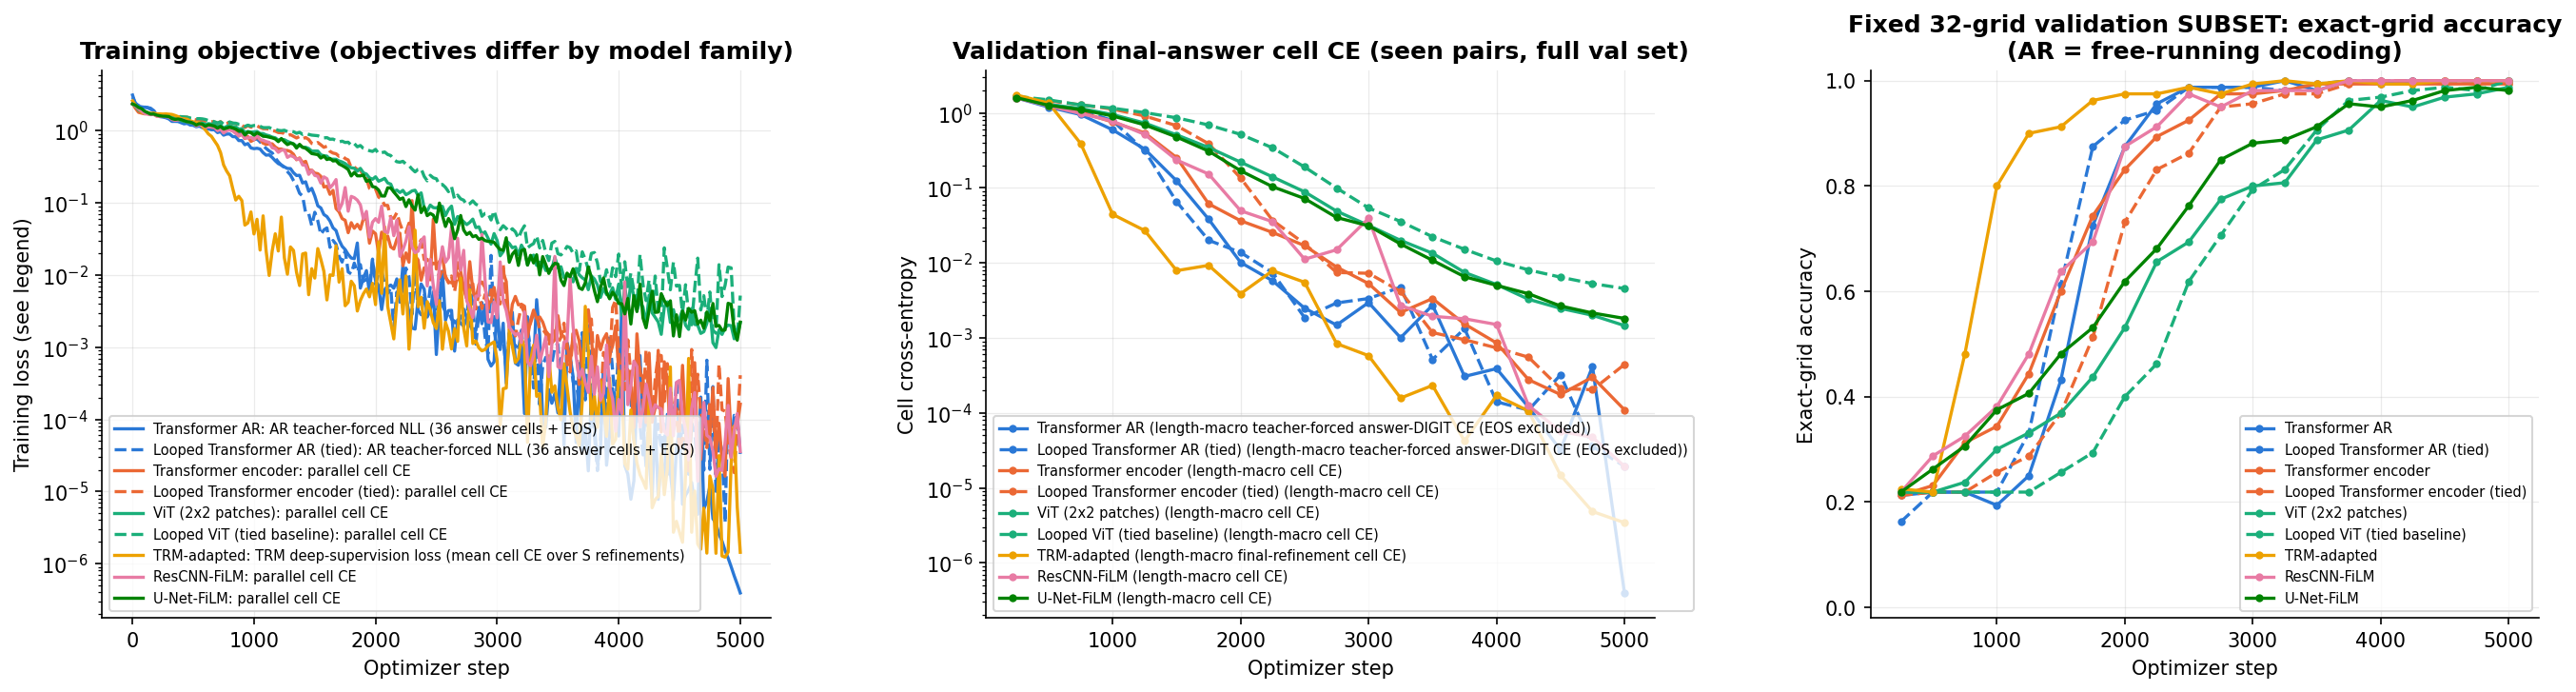

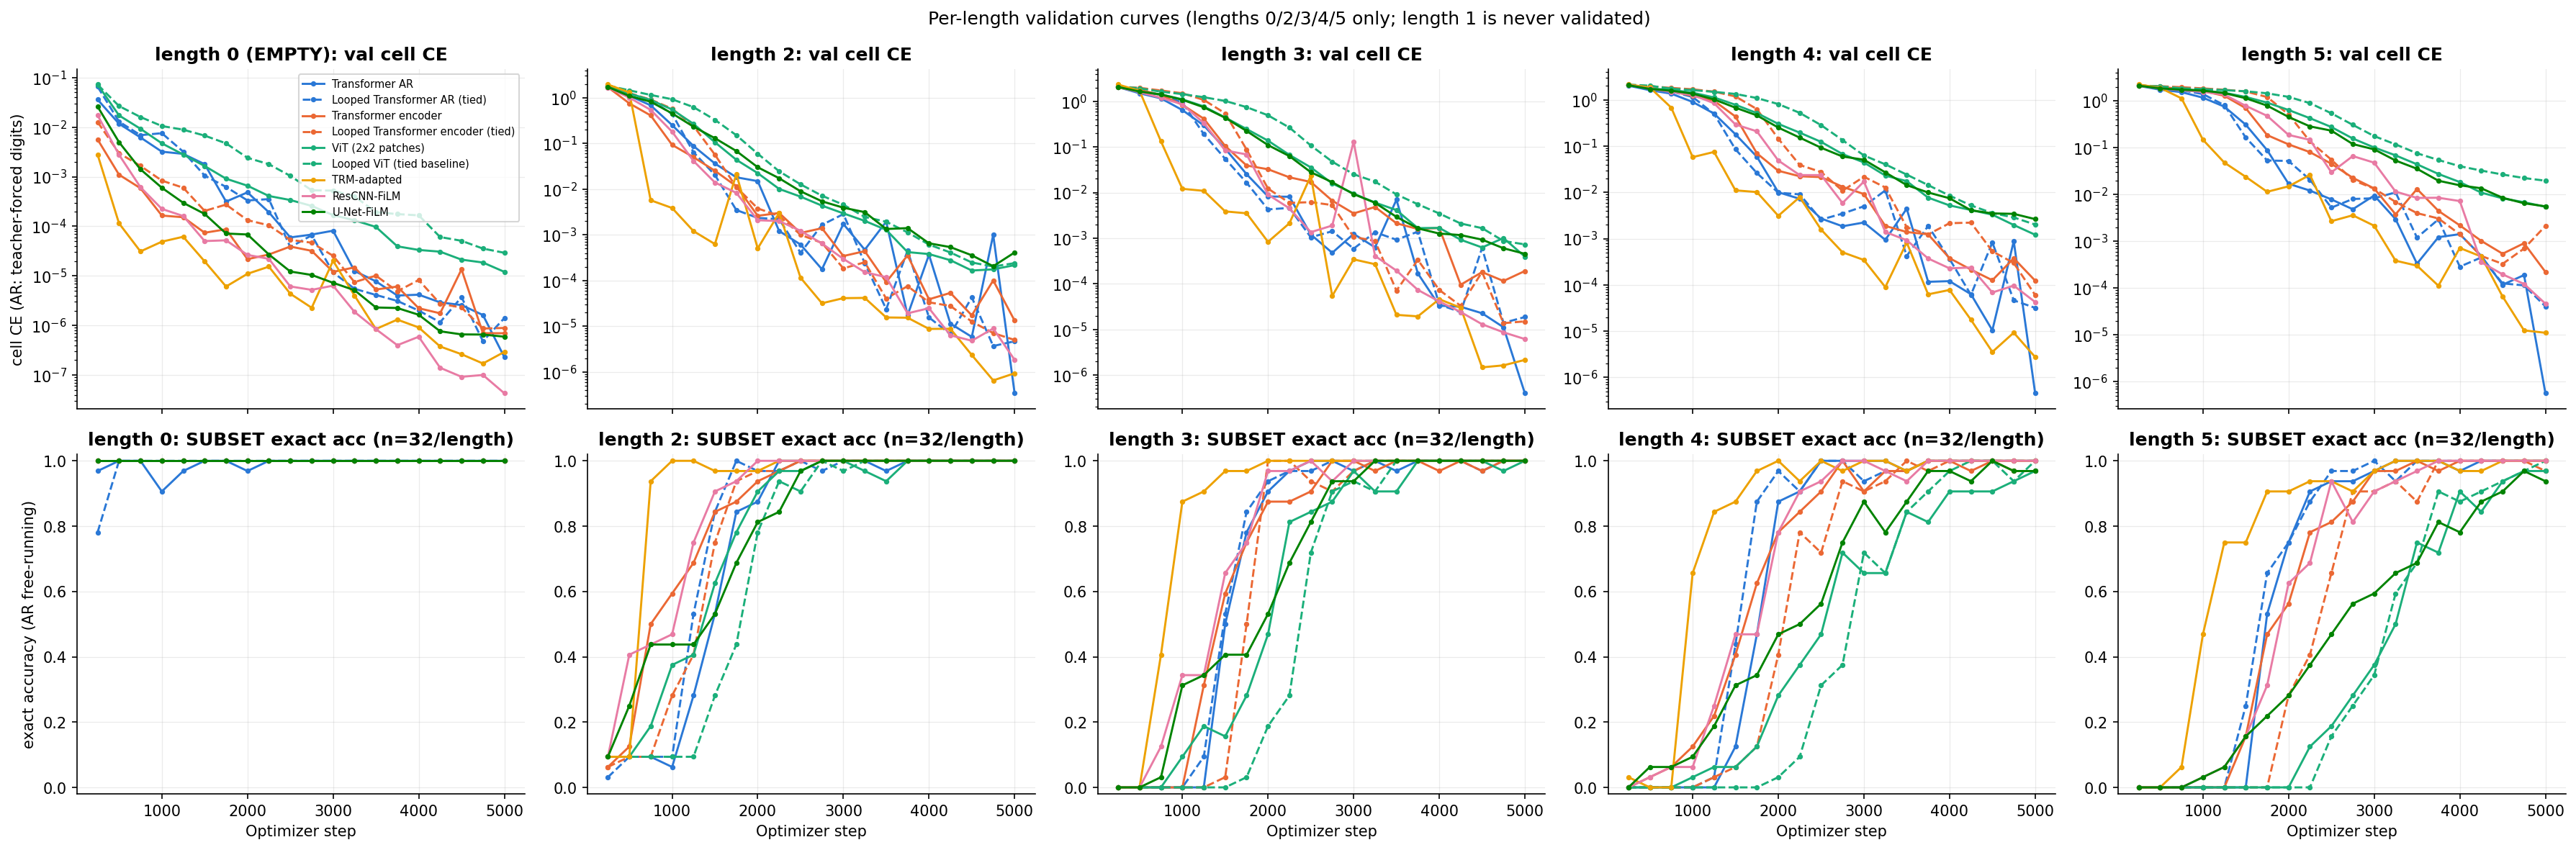

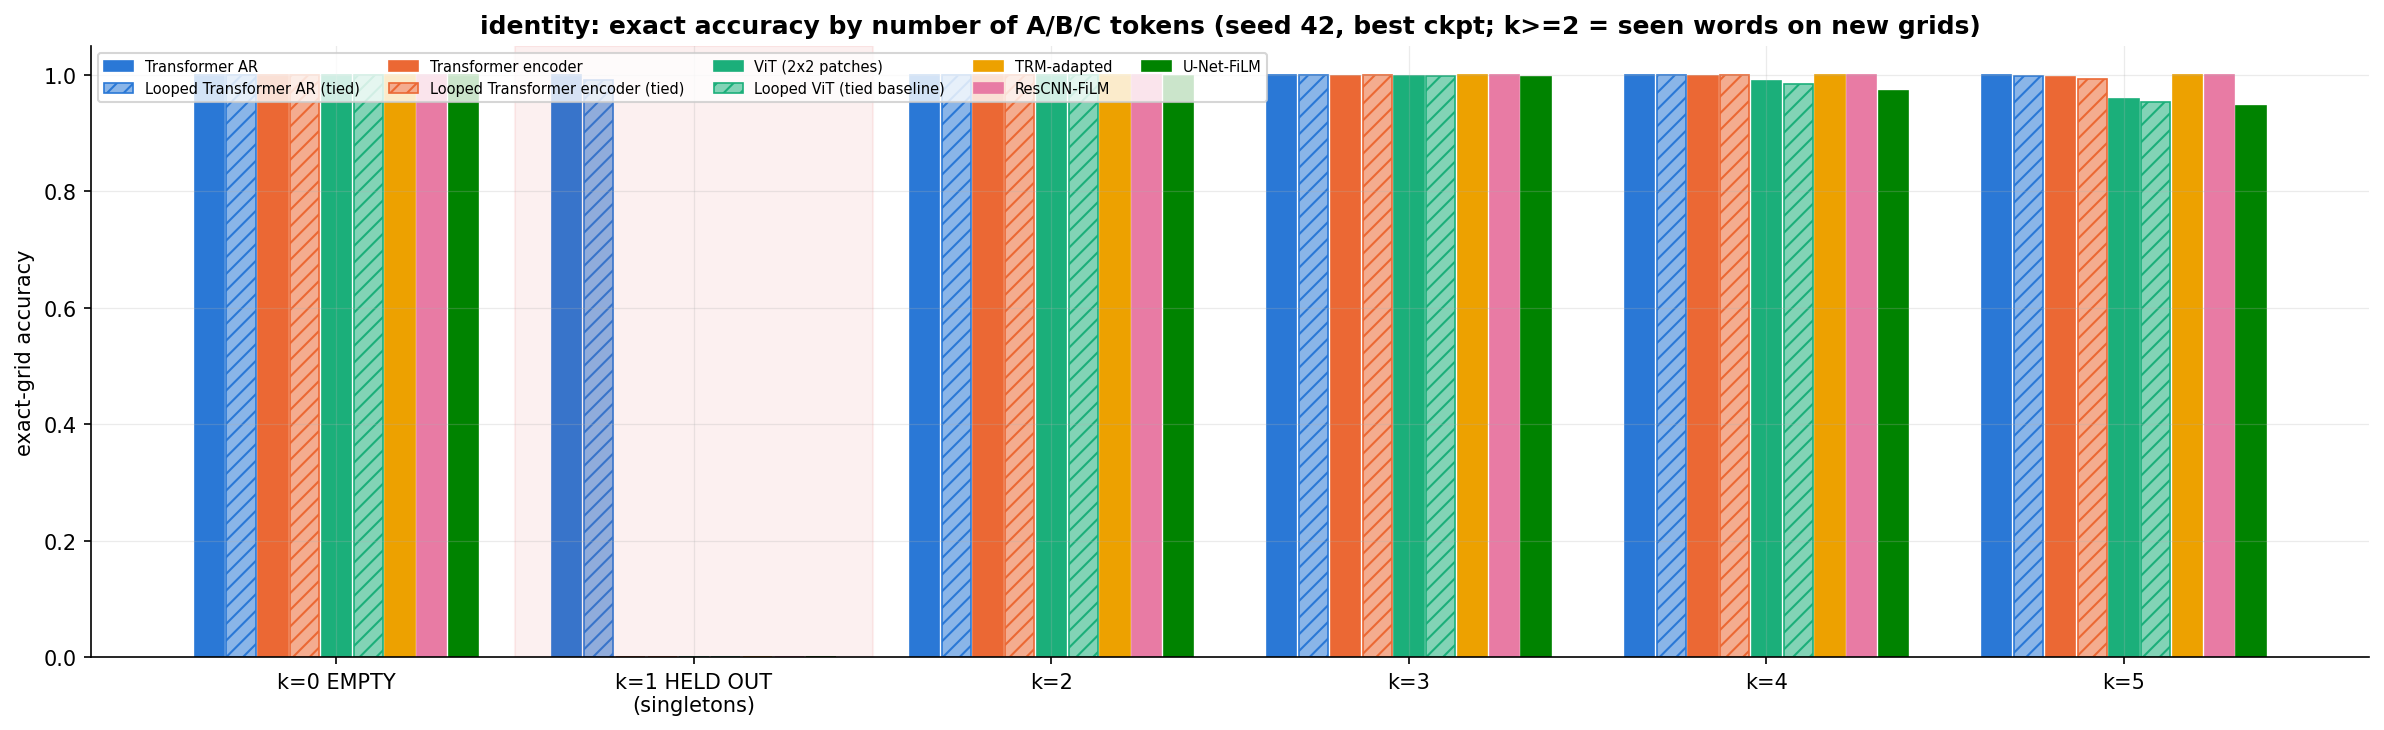

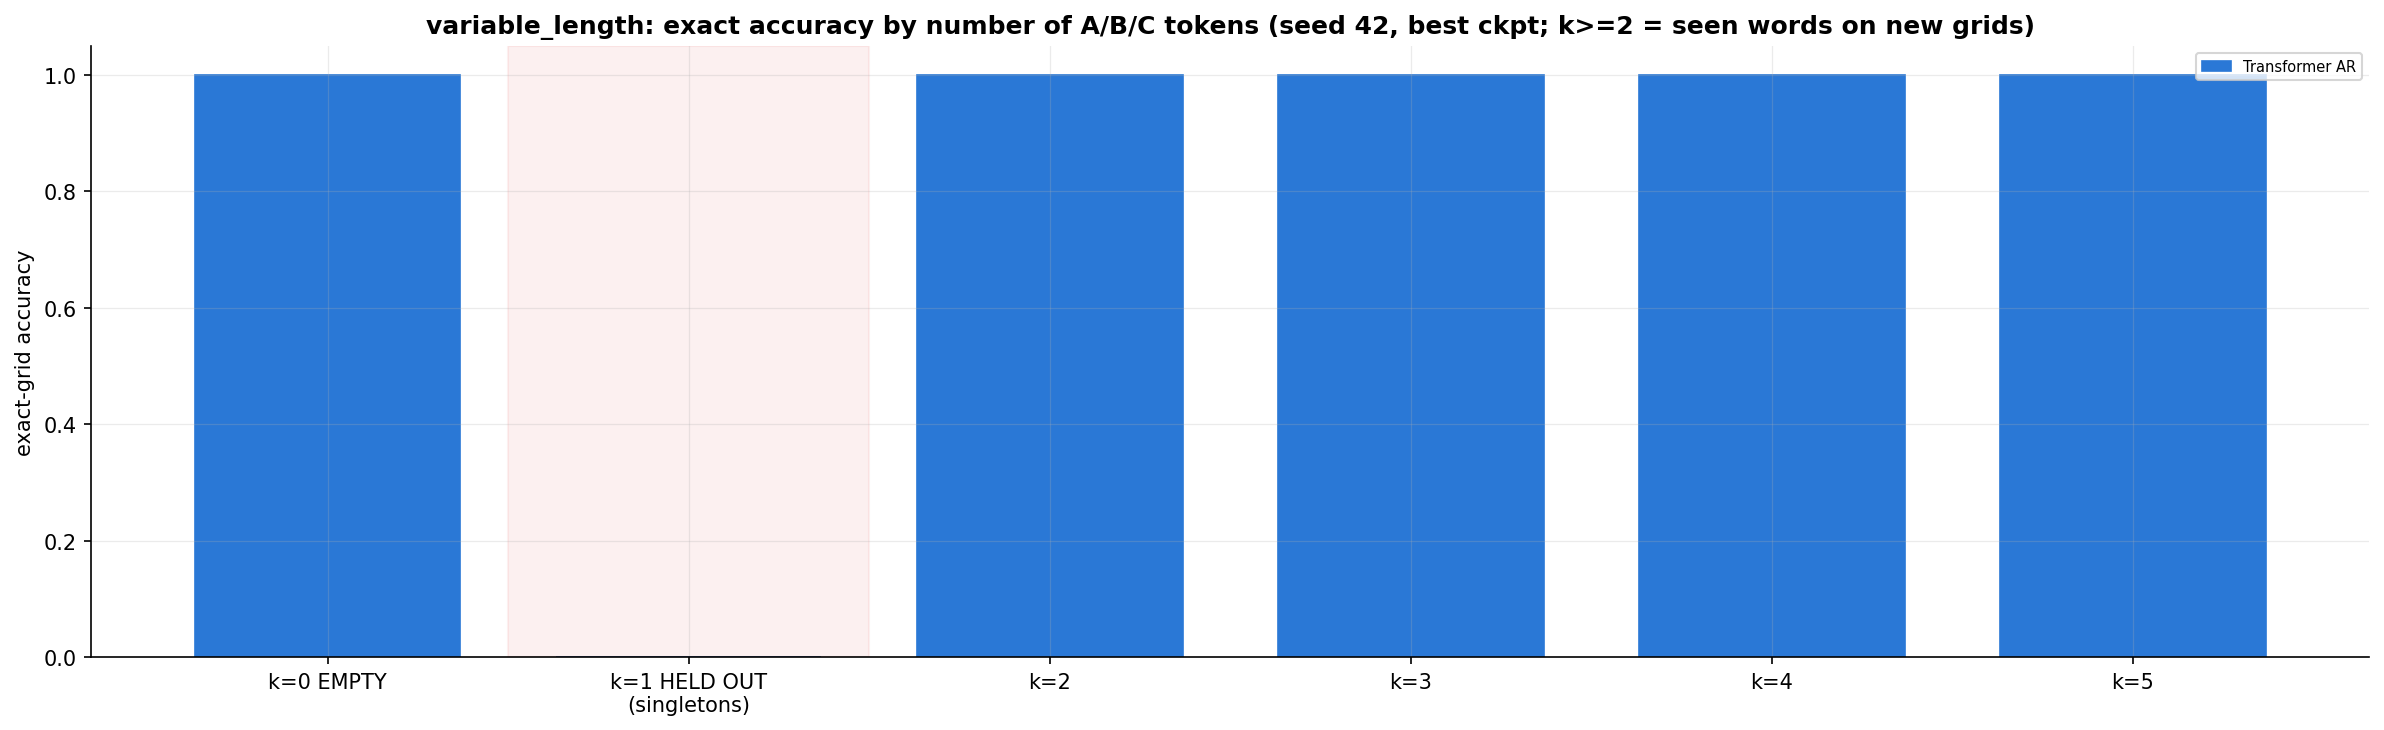

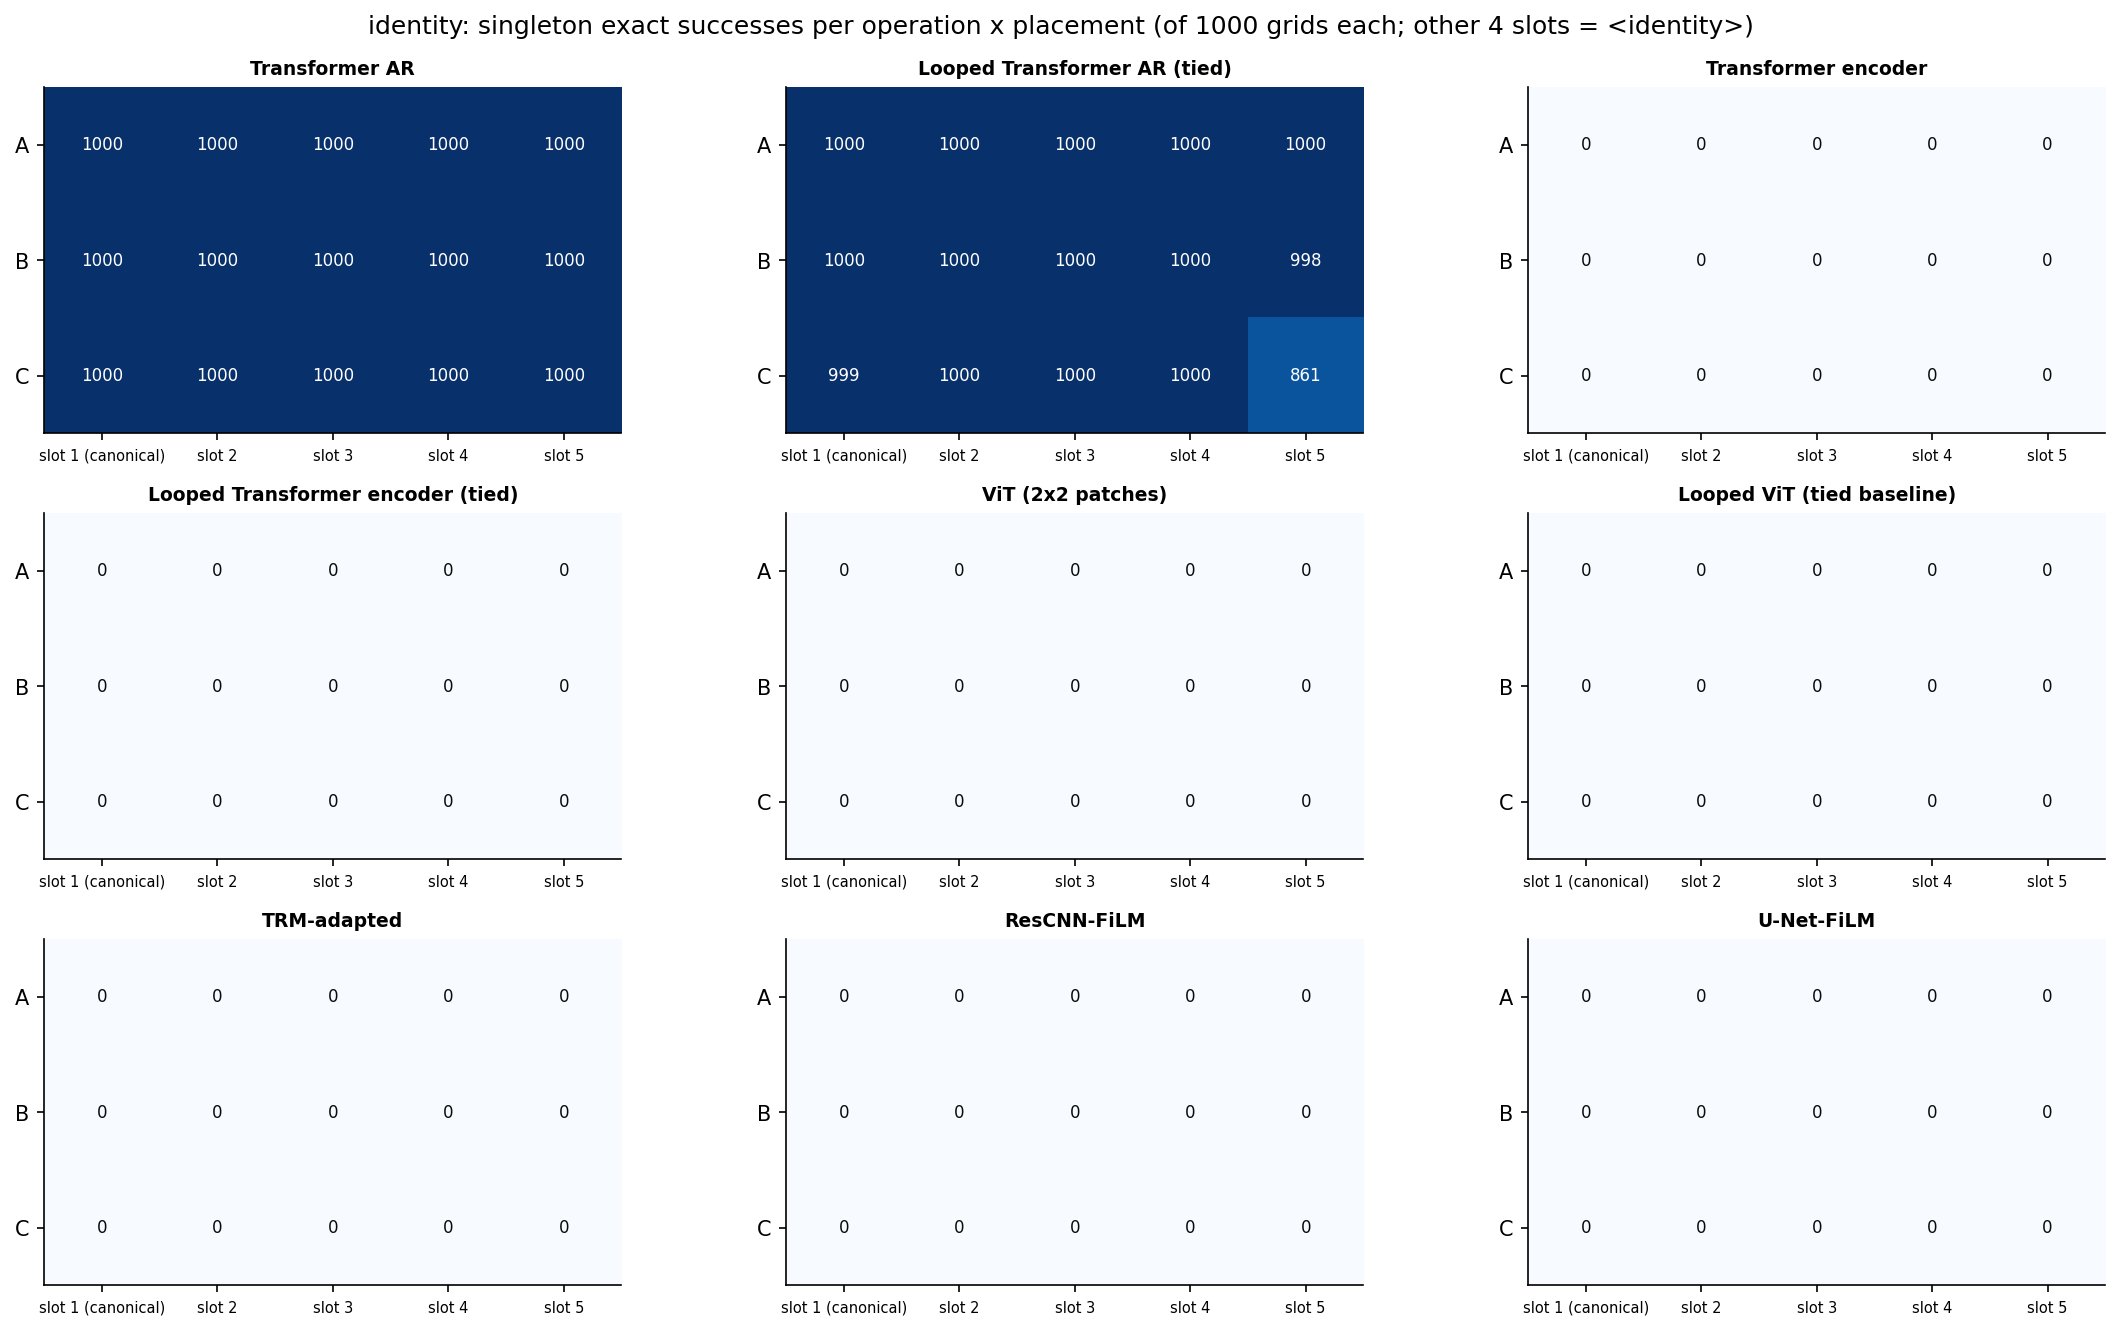

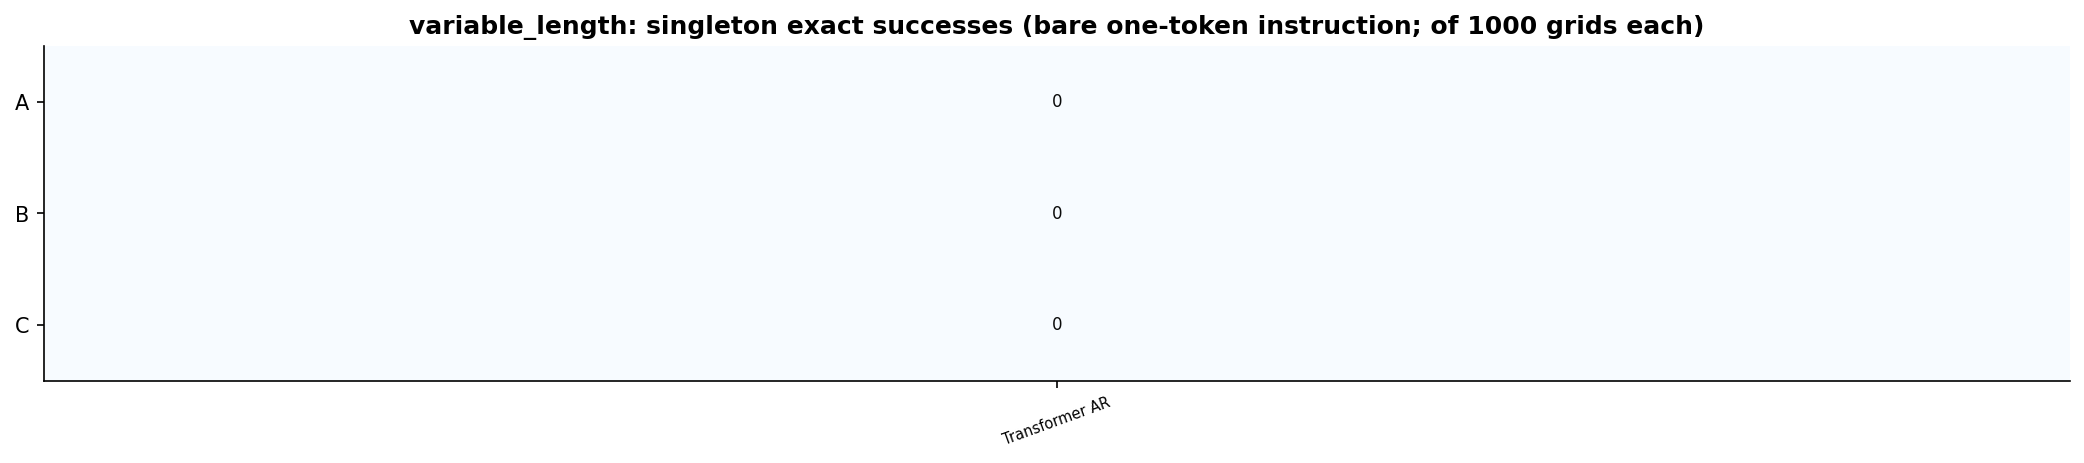

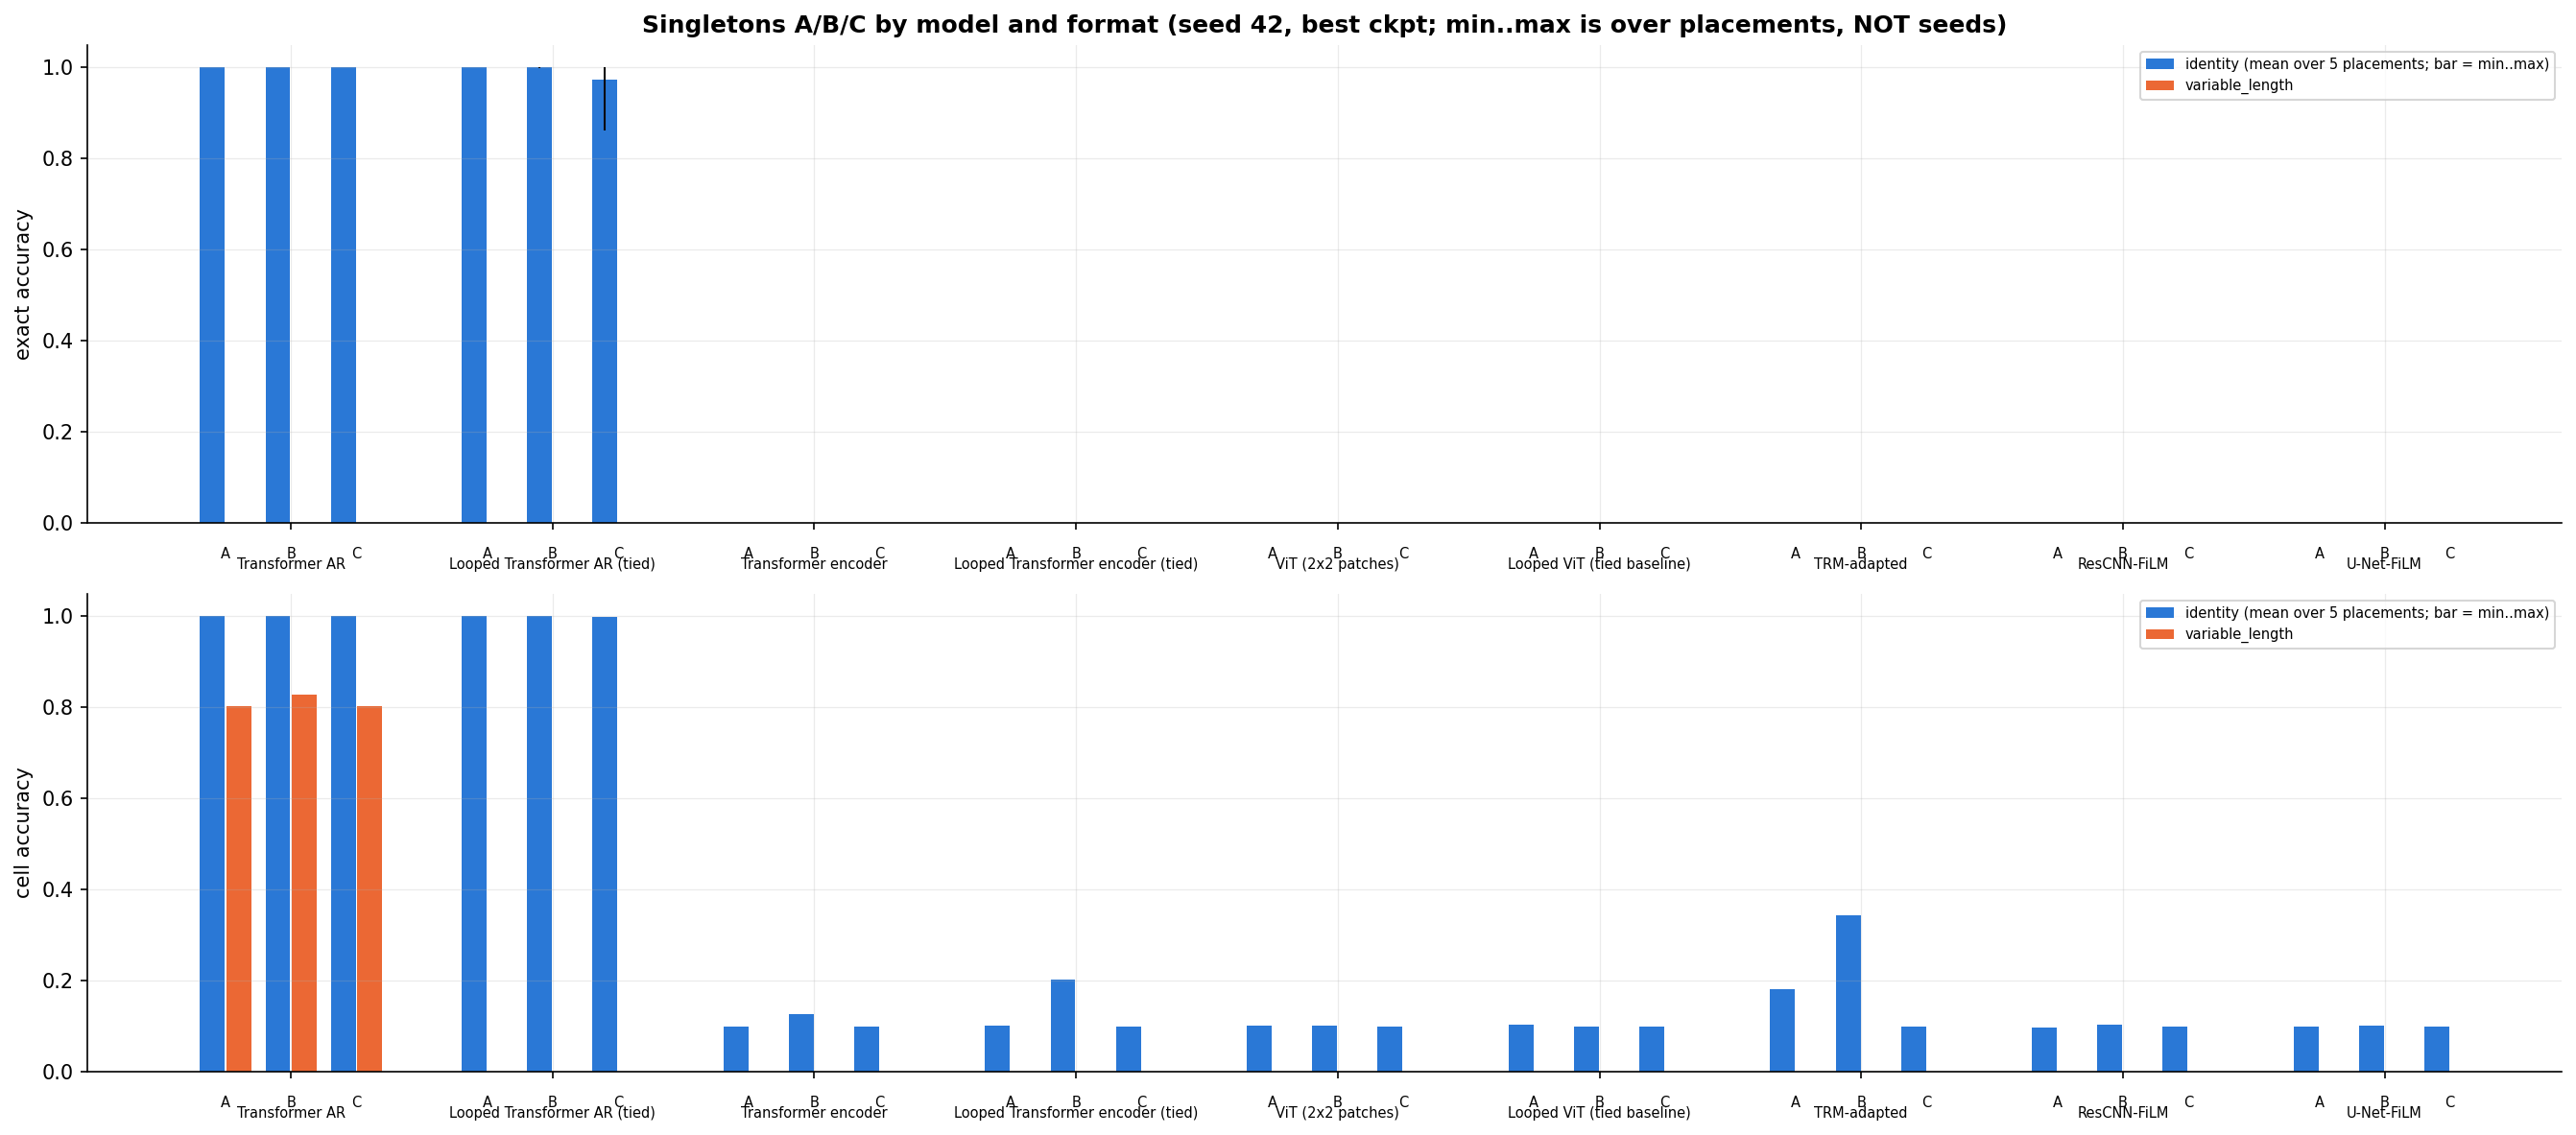

In [8]:
# --- Training curves, accuracy by k, singleton figures ------------------------------------------------------------
from decompositionality.reports import plot_training_curves
from decompositionality.mixed_reports import plot_length_curves
from decompositionality.idvar_reports import plot_by_k, plot_singletons
FIG = FAMILY_ROOT / "comparisons" / "figures"
paths = (plot_training_curves(cfg.experiment_dir, cfg.experiment_dir / "figures") or []) + \
        (plot_length_curves(cfg.experiment_dir, cfg.experiment_dir / "figures") or []) + plot_by_k(FAMILY_ROOT, FIG) + \
        plot_singletons(FAMILY_ROOT, FIG)
for p in paths:
    if str(p).endswith(".png"):
        display(Image(filename=str(p)))


Singleton diagnostics written to /content/drive/MyDrive/decompositionality_results/identity_varlen_02345_all_models/comparisons/singleton_diagnostics


,condition,model,status
0,identity,transformer_ar,analysed
1,identity,looped_transformer_ar,analysed
2,identity,transformer_encoder,analysed
3,identity,looped_transformer_encoder,analysed
4,identity,vit,analysed
5,identity,looped_vit,analysed
6,identity,trm,analysed
7,identity,rescnn_film,analysed
8,identity,unet_film,analysed
9,variable_length,transformer_ar,analysed


,condition,position,model,string,exact_correct,n,cell_acc,any_exact_group_match_count,dominant_wrong_unique_word,dominant_wrong_unique_share,stable_rule_selected_word,stable_rule_diag_exact_fidelity,argmax_map_diag_cell_fidelity
0,identity,1,transformer_ar,A,1000,1000,1.000000,1000,,0.000,A,1.000,1.000000
1,identity,1,transformer_ar,B,1000,1000,1.000000,1000,,0.000,B,1.000,1.000000
2,identity,1,transformer_ar,C,1000,1000,1.000000,1000,,0.000,C,1.000,1.000000
3,identity,2,transformer_ar,A,1000,1000,1.000000,1000,,0.000,A,1.000,1.000000
4,identity,2,transformer_ar,B,1000,1000,1.000000,1000,,0.000,B,1.000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
133,identity,5,unet_film,B,0,1000,0.099111,999,CB,0.999,CB,0.998,0.999944
134,identity,5,unet_film,C,0,1000,0.099111,1000,I,1.000,I,1.000,1.000000
135,variable_length,n/a,transformer_ar,A,0,1000,0.802694,0,,0.000,A,0.000,0.922167
136,variable_length,n/a,transformer_ar,B,0,1000,0.827639,0,,0.000,B,0.000,0.898222


,model,op,n_grids,grids_identical_across_all_5_placements,rate_identical_all_5,mean_pairwise_identical_rate
0,transformer_ar,A,1000,1000,1.000,1.0000
1,transformer_ar,B,1000,1000,1.000,1.0000
2,transformer_ar,C,1000,1000,1.000,1.0000
3,looped_transformer_ar,A,1000,1000,1.000,1.0000
4,looped_transformer_ar,B,1000,998,0.998,0.9992
5,looped_transformer_ar,C,1000,861,0.861,0.9441
6,transformer_encoder,A,1000,0,0.000,0.0915
7,transformer_encoder,B,1000,0,0.000,0.0086
8,transformer_encoder,C,1000,1000,1.000,1.0000
9,looped_transformer_encoder,A,1000,0,0.000,0.4303


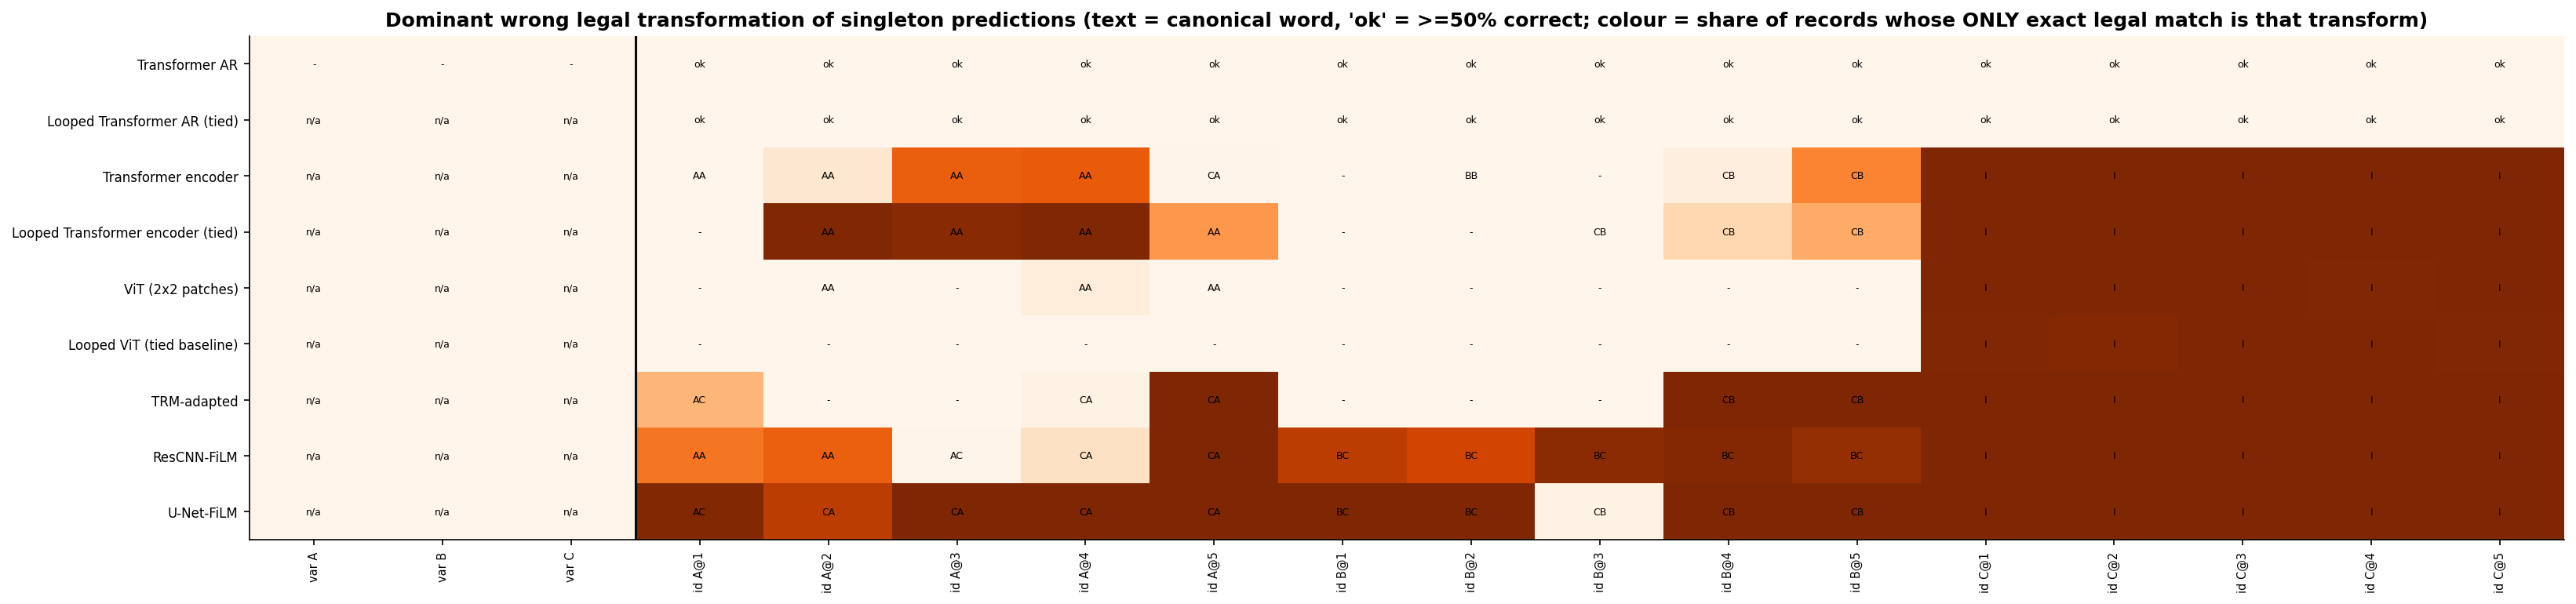

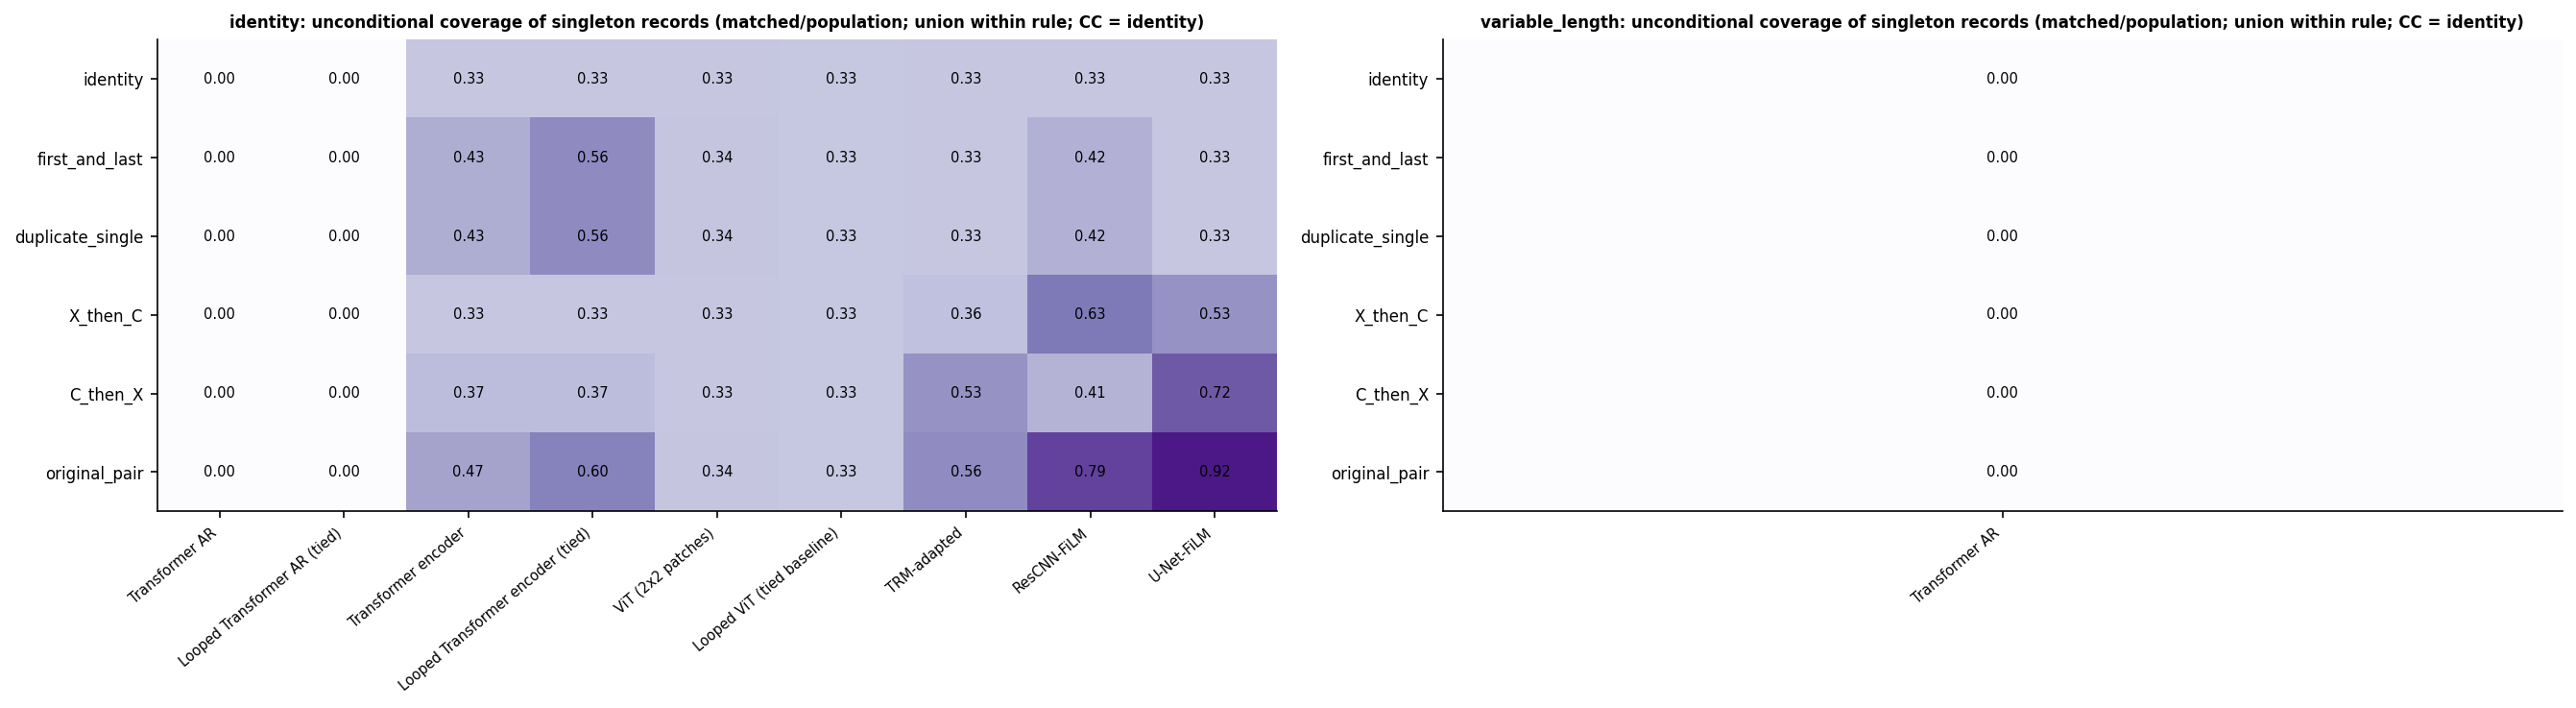

In [9]:
# --- Singleton diagnostics (288-transform matching, hypotheses with denominators, FIT/DIAG maps, placement
#     consistency) for every model available in EITHER format (missing runs are listed, never zero-filled) ------------
from decompositionality.idvar_reports import singleton_diagnostics, plot_dominant_and_coverage
diag = singleton_diagnostics(FAMILY_ROOT, MODELS)
display(diag["status"])
cols = ["condition", "position", "model", "string", "exact_correct", "n", "cell_acc", "any_exact_group_match_count",
        "dominant_wrong_unique_word", "dominant_wrong_unique_share", "stable_rule_selected_word",
        "stable_rule_diag_exact_fidelity", "argmax_map_diag_cell_fidelity"]
display(diag["per_string"][[c for c in cols if c in diag["per_string"]]])
display(diag["consistency"])
for p in plot_dominant_and_coverage(diag, FIG):
    if str(p).endswith(".png"):
        display(Image(filename=str(p)))


In [10]:
# --- Paired format comparison (rerun this cell alone once both notebooks are done; no retraining) -----------------
from decompositionality.idvar_reports import compare_formats, status_table
cmp = compare_formats(FAMILY_ROOT, MODELS)
display(cmp["status"])
if cmp["summary"] is not None:
    display(cmp["summary"]); display(cmp["singletons"]); display(cmp["seen"])


Format comparison: transformer_ar: compared; looped_transformer_ar: not yet available: variable_length missing; transformer_encoder: not yet available: variable_length missing; looped_transformer_encoder: not yet available: variable_length missing; vit: not yet available: variable_length missing; looped_vit: not yet available: variable_length missing; trm: not yet available: variable_length missing; rescnn_film: not yet available: variable_length missing; unet_film: not yet available: variable_length missing


,model,status
0,transformer_ar,compared
1,looped_transformer_ar,not yet available: variable_length missing
2,transformer_encoder,not yet available: variable_length missing
3,looped_transformer_encoder,not yet available: variable_length missing
4,vit,not yet available: variable_length missing
5,looped_vit,not yet available: variable_length missing
6,trm,not yet available: variable_length missing
7,rescnn_film,not yet available: variable_length missing
8,unet_film,not yet available: variable_length missing


,model,op,variable_exact,n_grids,identity_exact_mean_over_slots,identity_exact_min,identity_exact_max,identity_slot1_exact
0,transformer_ar,A,0,1000,1000.0,1000,1000,1000
1,transformer_ar,B,0,1000,1000.0,1000,1000,1000
2,transformer_ar,C,0,1000,1000.0,1000,1000,1000


,model,op,identity_slot,n_grids,variable_exact,identity_exact,both_correct,only_variable_correct,only_identity_correct,both_wrong,identical_prediction_rate
0,transformer_ar,A,1,1000,0,1000,0,0,1000,0,0.0
1,transformer_ar,B,1,1000,0,1000,0,0,1000,0,0.0
2,transformer_ar,C,1,1000,0,1000,0,0,1000,0,0.0
3,transformer_ar,A,2,1000,0,1000,0,0,1000,0,0.0
4,transformer_ar,B,2,1000,0,1000,0,0,1000,0,0.0
5,transformer_ar,C,2,1000,0,1000,0,0,1000,0,0.0
6,transformer_ar,A,3,1000,0,1000,0,0,1000,0,0.0
7,transformer_ar,B,3,1000,0,1000,0,0,1000,0,0.0
8,transformer_ar,C,3,1000,0,1000,0,0,1000,0,0.0
9,transformer_ar,A,4,1000,0,1000,0,0,1000,0,0.0


,model,k,n,identity_exact,variable_exact,both_correct,only_identity_correct,only_variable_correct,both_wrong
0,transformer_ar,0,1000,1000,1000,1000,0,0,0
1,transformer_ar,2,9000,9000,9000,9000,0,0,0
2,transformer_ar,3,27000,27000,27000,27000,0,0,0
3,transformer_ar,4,81000,81000,81000,81000,0,0,0
4,transformer_ar,5,243000,243000,243000,243000,0,0,0


In [11]:
# --- Export + per-model status (this notebook is complete only if EVERY model is trained and evaluated) -----------
from decompositionality.mixed_reports import make_compact_archive
st = status_table(FAMILY_ROOT, MODELS); display(st)
mine = st[st.condition == CONDITION]
make_compact_archive(cfg.experiment_dir)
if not (mine.trained.all() and mine.evaluated.all()):
    print("INCOMPLETE:", mine[~(mine.trained & mine.evaluated)].model.tolist(), "-> rerun Run all to resume")
else:
    print(f"{CONDITION}: all {len(mine)} models trained and evaluated.")


,condition,model,trained,evaluated,records
0,identity,transformer_ar,True,True,376000.0
1,identity,looped_transformer_ar,True,True,376000.0
2,identity,transformer_encoder,True,True,376000.0
3,identity,looped_transformer_encoder,True,True,376000.0
4,identity,vit,True,True,376000.0
5,identity,looped_vit,True,True,376000.0
6,identity,trm,True,True,376000.0
7,identity,rescnn_film,True,True,376000.0
8,identity,unet_film,True,True,376000.0
9,variable_length,transformer_ar,True,True,364000.0


Compact archive: /content/drive/MyDrive/decompositionality_results/identity_varlen_02345_all_models/identity/results_identity.zip (32.6 MiB)
identity: all 9 models trained and evaluated.


Outputs: `<RESULTS_ROOT>/identity_varlen_02345_all_models/` -> `manifests/`, `identity/<model>`, `variable_length/<model>` (runs, eval with `ARTIFACT.json`, audits, figures), `artifact_index.json`, `comparisons/` (figures, singleton diagnostics, format comparison).